# Ensemble Learning for Multiclass Classification
## Stacking, AdaBoost and Majority Voting

**Dataset:** scikit-learn Wine Recognition (178 observations, 13 numerical features, 3 classes)  
**Student:** Paras Satpute

### Abstract
This experiment compares four individual classifiers with three ensemble approaches: stacking with a Logistic Regression meta-classifier, AdaBoost with decision-tree stumps, and hard majority voting. All models use the same stratified hold-out split. Five-fold stratified cross-validation is performed on training data only. Evaluation includes accuracy, macro precision, macro recall, macro F1, weighted F1, multiclass ROC-AUC, confusion matrices and runtime. Results are generated by executing the notebook and are not assumed in advance.

### Objectives
1. Explore a real multiclass classification dataset.
2. Train Logistic Regression, Decision Tree, KNN and RBF-SVM baselines.
3. Implement StackingClassifier, AdaBoostClassifier and hard VotingClassifier.
4. Compare models using consistent data partitions and classification metrics.
5. Explain model suitability, limitations, ethical considerations and future improvements.

### Why this dataset?
The Wine dataset is a compact, built-in, reproducible dataset with 13 continuous chemical measurements and three target classes. It is appropriate for demonstrating scaling-sensitive and tree-based models without requiring external downloads. It is intended here for education, not real-world wine quality, safety or authenticity decisions.

## 1. Ensemble learning concepts

- **Stacking:** base learners produce predictions that become inputs to a second-level meta-classifier. Here, Logistic Regression is the meta-classifier. Cross-validated predictions train the meta-model.
- **AdaBoost:** weak learners are trained sequentially. Later learners focus more on observations misclassified earlier. Decision-tree stumps (`max_depth=1`) are used as weak learners.
- **Hard voting:** each base classifier casts one class vote; the class with the most votes is selected. No meta-classifier is trained.
- **Base classifiers:** Logistic Regression (linear probabilistic baseline), Decision Tree (nonlinear rules), KNN (distance-based learner), and RBF-SVM (nonlinear margin-based learner).

Ensembles tend to be most useful when their base learners have complementary error patterns. A larger ensemble is not automatically better; added complexity must be justified by measured performance.

## 2. Import libraries and set reproducibility

In [1]:
import sys, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import StackingClassifier, AdaBoostClassifier, VotingClassifier

SEED = 42
np.random.seed(SEED)
print("Python:", sys.version.split()[0], "| scikit-learn:", sklearn.__version__)

Python: 3.13.5 | scikit-learn: 1.8.0


## 3. Load and inspect the dataset

In [2]:
wine = load_wine(as_frame=True)
X, y = wine.data.copy(), wine.target.copy()
class_names = list(wine.target_names)
df = X.copy()
df["target"] = y
df["class_name"] = y.map(dict(enumerate(class_names)))
print("Shape:", df.shape, "| Features:", X.shape[1], "| Classes:", class_names)
display(df.head())

Shape: (178, 15) | Features: 13 | Classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,class_name
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


In [3]:
print("Class counts:")
display(df["class_name"].value_counts().to_frame("count"))
print("Missing values:")
display(X.isna().sum().to_frame("missing values"))
print("Descriptive statistics:")
display(X.describe().T)

Class counts:


,count
class_name,
class_1,71
class_0,59
class_2,48


Missing values:


,missing values
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


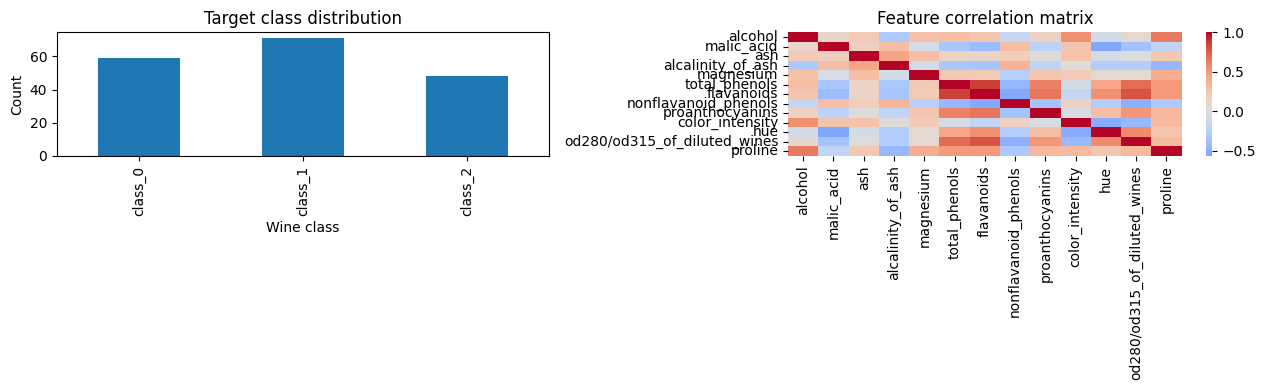

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df["class_name"].value_counts().reindex(class_names).plot(kind="bar", ax=ax[0])
ax[0].set_title("Target class distribution")
ax[0].set_xlabel("Wine class")
ax[0].set_ylabel("Count")
sns.heatmap(X.corr(), cmap="coolwarm", center=0, ax=ax[1])
ax[1].set_title("Feature correlation matrix")
plt.tight_layout()
plt.show()

## 4. Split data and prevent leakage

An 80:20 stratified split preserves class proportions. The test set is held back for final evaluation. Scaling is included inside pipelines for Logistic Regression, KNN and SVM, so each cross-validation fold learns its own scaler from that fold's training data. Decision trees do not require standardisation.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train proportions:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("Test proportions:", y_test.value_counts(normalize=True).sort_index().round(3).to_dict())

Train: (142, 13)  Test: (36, 13)
Train proportions: {0: 0.331, 1: 0.401, 2: 0.268}
Test proportions: {0: 0.333, 1: 0.389, 2: 0.278}


## 5. Define individual base classifiers

In [6]:
base_models = {
    "Logistic Regression": Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=SEED))
    ]),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "KNN": Pipeline([
        ("scale", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "SVM (RBF)": Pipeline([
        ("scale", StandardScaler()),
        ("model", SVC(kernel="rbf", C=1.0, gamma="scale",
                      probability=True, random_state=SEED))
    ])
}
for name in base_models:
    print(name)

Logistic Regression
Decision Tree
KNN
SVM (RBF)


## 6. Build the three ensemble models

**Stacking:** the four base learners feed a Logistic Regression meta-classifier. Five-fold out-of-fold predictions are used to train the meta-classifier.

**AdaBoost:** 100 decision-tree stumps are trained sequentially with learning rate 0.5. These are baseline hyperparameters, not a claim of global optimality.

**Hard voting:** the four base learners each contribute one vote. The most-voted class is returned. This directly implements majority voting.

In [7]:
estimators = [(k, v) for k, v in [
    ("lr", base_models["Logistic Regression"]),
    ("tree", base_models["Decision Tree"]),
    ("knn", base_models["KNN"]),
    ("svm", base_models["SVM (RBF)"])
]]
stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=3000, random_state=SEED),
    cv=5, stack_method="auto", passthrough=False, n_jobs=-1
)
stump = DecisionTreeClassifier(max_depth=1, random_state=SEED)
try:
    adaboost = AdaBoostClassifier(estimator=stump, n_estimators=100,
                                  learning_rate=0.5, random_state=SEED)
except TypeError:
    adaboost = AdaBoostClassifier(base_estimator=stump, n_estimators=100,
                                  learning_rate=0.5, random_state=SEED)
voting = VotingClassifier(estimators=estimators, voting="hard", n_jobs=-1)
models = {**base_models, "Stacking": stacking, "AdaBoost": adaboost,
          "Hard Voting": voting}
print("Models:", list(models))

Models: ['Logistic Regression', 'Decision Tree', 'KNN', 'SVM (RBF)', 'Stacking', 'AdaBoost', 'Hard Voting']


## 7. Training-only five-fold cross-validation

Cross-validation is performed on the training partition only. Macro F1 is the primary validation metric because it weights each class equally. The test set is not used for model selection.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {"accuracy":"accuracy", "precision_macro":"precision_macro",
           "recall_macro":"recall_macro", "f1_macro":"f1_macro"}
cv_rows = []
for name, model in models.items():
    t0 = time.perf_counter()
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=-1, return_train_score=False)
    cv_rows.append({
        "Model": name, "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Accuracy SD": scores["test_accuracy"].std(),
        "CV Macro F1": scores["test_f1_macro"].mean(),
        "CV Macro F1 SD": scores["test_f1_macro"].std(),
        "CV Time (s)": time.perf_counter()-t0
    })
cv_results = pd.DataFrame(cv_rows).sort_values("CV Macro F1", ascending=False)
display(cv_results.round(4))

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/daemon.py", line 124, in start_daemon
TimeoutError: Timed out waiting for artifact tool daemon socket. Set ARTIFACT_TOOL_RPC_DAEMON_STARTUP_TIMEOUT_S=<seconds> to increase the limit.


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 772, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/connection.py", line 37, in get_or_create_client
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/daemon.py", line 124, in start_daemon
TimeoutError: Timed out waiting for artifact tool daemon socket. Set ARTIFACT_TOOL_RPC_DAEMON_STARTUP_TIMEOUT_S=<seconds> to increase the limit.


Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

Spreadsheet runtime warmup failed during python startup
Traceback (most recent call last):
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/patches/warm_spreadsheet_runtime_on_startup.py", line 26, in warm_spreadsheet_runtime_on_startup
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 785, in warm_spreadsheet_runtime
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 718, in _warm_feature_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/spreadsheet_warmup.py", line 509, in _warm_drawing_and_image_flows
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/generated/interface/models.py", line 32861, in bring_to_front
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/remote.py", line 764, in __call__
  File "/tmp/tmp.QlpUkOUI9D/artifact_tool_v2-2.8.66/artifact_tool/rpc/client.py", line 175, in call
artifact_tool.rpc.client.Remot

,Model,CV Accuracy,CV Accuracy SD,CV Macro F1,CV Macro F1 SD,CV Time (s)
3,SVM (RBF),0.9862,0.0169,0.9865,0.0167,0.2842
6,Hard Voting,0.9860,0.0172,0.9860,0.0172,2.1264
0,Logistic Regression,0.9791,0.0277,0.9796,0.0273,14.2115
4,Stacking,0.9793,0.0276,0.9794,0.0283,2.0997
5,AdaBoost,0.9510,0.0272,0.9518,0.0255,2.9751
2,KNN,0.9507,0.0353,0.9512,0.0365,0.1978
1,Decision Tree,0.9022,0.0586,0.9055,0.0569,0.2227


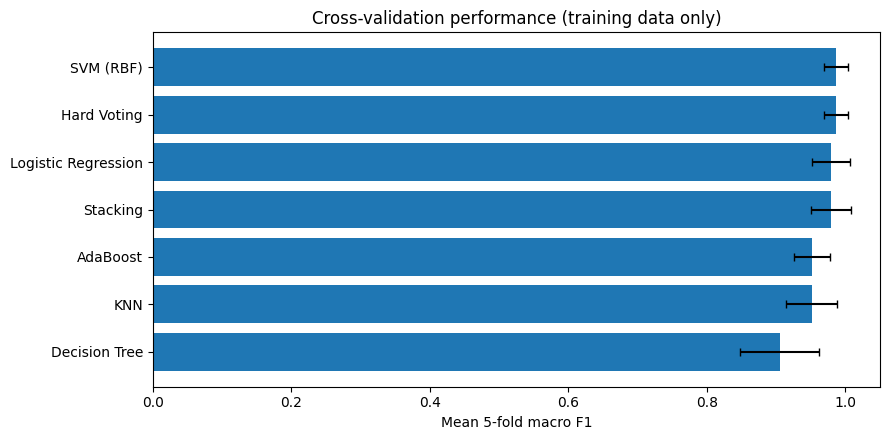

In [9]:
p = cv_results.sort_values("CV Macro F1")
plt.figure(figsize=(9, 4.5))
plt.barh(p["Model"], p["CV Macro F1"], xerr=p["CV Macro F1 SD"], capsize=3)
plt.xlim(0, 1.05); plt.xlabel("Mean 5-fold macro F1")
plt.title("Cross-validation performance (training data only)")
plt.tight_layout(); plt.show()

## 8. Fit final models and evaluate the held-out test set

All seven models use the exact same training and test observations. Macro metrics give each class equal weight; weighted F1 accounts for class support. Multiclass ROC-AUC is calculated with a one-vs-rest strategy from predicted probabilities when supported.

In [10]:
results, fitted, preds, probas = [], {}, {}, {}
for name, model in models.items():
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter()-t0
    t0 = time.perf_counter()
    yp = model.predict(X_test)
    pred_s = time.perf_counter()-t0
    fitted[name], preds[name] = model, yp
    row = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, yp),
        "Precision (macro)": precision_score(y_test, yp, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, yp, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, yp, average="macro", zero_division=0),
        "F1 (weighted)": f1_score(y_test, yp, average="weighted", zero_division=0),
        "Fit time (s)": fit_s, "Predict time (s)": pred_s,
        "ROC-AUC (OvR macro)": np.nan
    }
    if hasattr(model, "predict_proba"):
        try:
            pr = model.predict_proba(X_test)
            probas[name] = pr
            row["ROC-AUC (OvR macro)"] = roc_auc_score(
                y_test, pr, multi_class="ovr", average="macro")
        except Exception:
            pass
    results.append(row)
test_results = pd.DataFrame(results).sort_values("F1 (macro)", ascending=False)
display(test_results.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),Fit time (s),Predict time (s),ROC-AUC (OvR macro)
5,AdaBoost,0.9722,0.9744,0.9762,0.9743,0.9723,0.3004,0.0145,0.9989
2,KNN,0.9722,0.9697,0.9762,0.9718,0.9724,0.0026,0.0055,0.9988
0,Logistic Regression,0.9722,0.9778,0.9667,0.9710,0.9720,0.0299,0.0066,1.0000
4,Stacking,0.9722,0.9778,0.9667,0.9710,0.9720,3.3257,0.0184,1.0000
3,SVM (RBF),0.9722,0.9778,0.9667,0.9710,0.9720,0.0096,0.0026,1.0000
6,Hard Voting,0.9722,0.9778,0.9667,0.9710,0.9720,0.0580,0.0204,NaN
1,Decision Tree,0.9444,0.9583,0.9389,0.9457,0.9450,0.0033,0.0009,0.9543


### Metric interpretation
- **Accuracy:** overall fraction of correct predictions.
- **Macro precision/recall/F1:** calculate the metric per class and average equally; useful when class-wise balance matters.
- **Weighted F1:** averages class F1 weighted by class support.
- **ROC-AUC (one-vs-rest macro):** measures class score ranking quality across one-vs-rest comparisons. Interpret alongside confusion matrices and threshold-dependent metrics.
- **Runtime:** measured on the current environment and may vary with hardware and software versions.

## 9. Class-wise classification reports

In [11]:
for name, yp in preds.items():
    print("\\n" + "="*65 + "\\n" + name)
    print(classification_report(y_test, yp, target_names=class_names, zero_division=0))

\n=================================================================\nLogistic Regression
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        12
     class_1       0.93      1.00      0.97        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36

\n=================================================================\nDecision Tree
              precision    recall  f1-score   support

     class_0       1.00      0.92      0.96        12
     class_1       0.88      1.00      0.93        14
     class_2       1.00      0.90      0.95        10

    accuracy                           0.94        36
   macro avg       0.96      0.94      0.95        36
weighted avg       0.95      0.94      0.94        36

\n================================================================

## 10. Confusion matrices

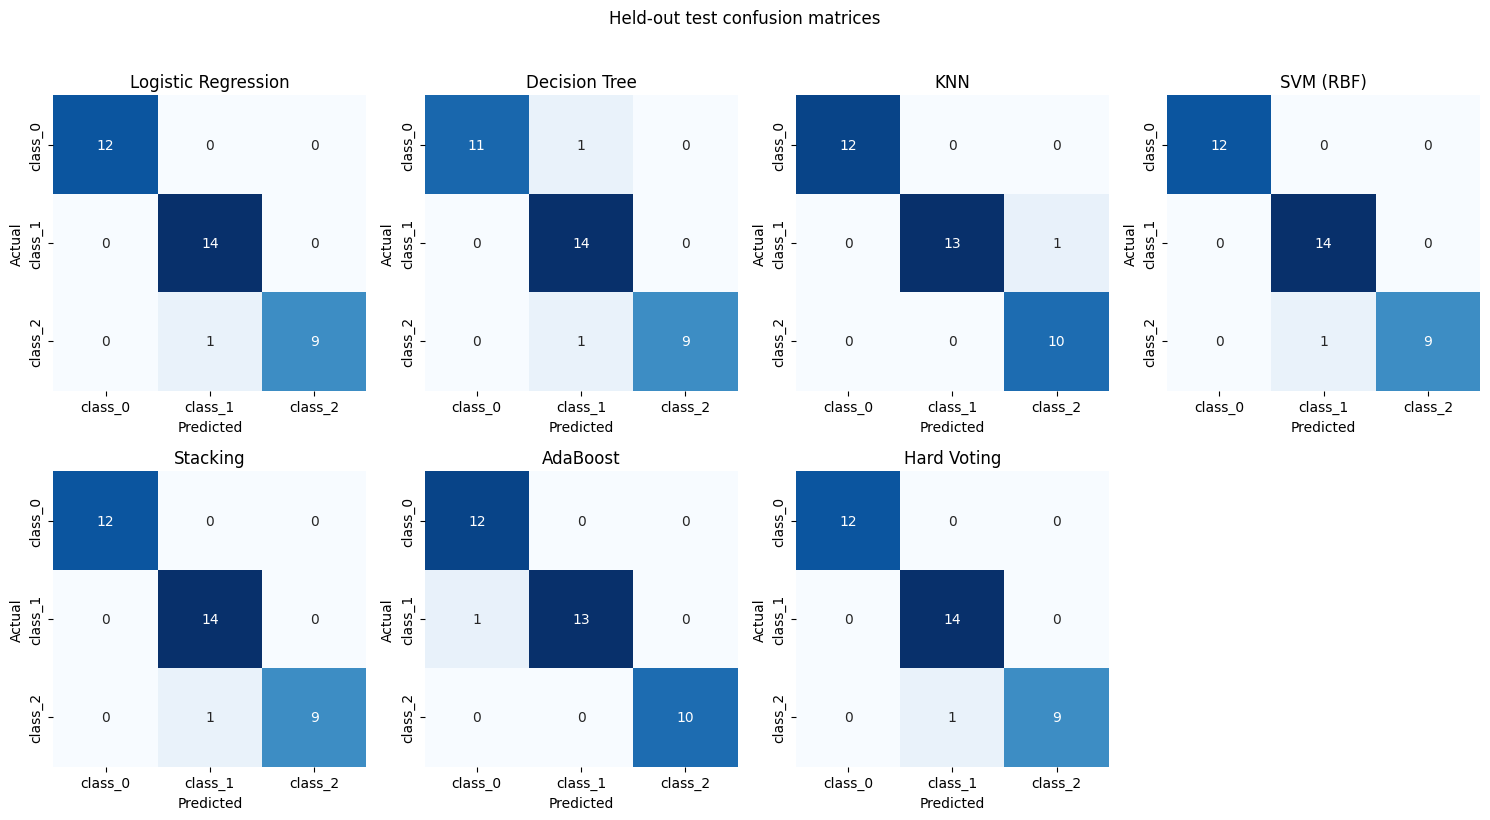

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
for ax, (name, yp) in zip(axes.ravel(), preds.items()):
    sns.heatmap(confusion_matrix(y_test, yp), annot=True, fmt="d",
                cmap="Blues", cbar=False, xticklabels=class_names,
                yticklabels=class_names, ax=ax)
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
for ax in axes.ravel()[len(preds):]:
    ax.axis("off")
plt.suptitle("Held-out test confusion matrices", y=1.02)
plt.tight_layout(); plt.show()

## 11. Compare test metrics

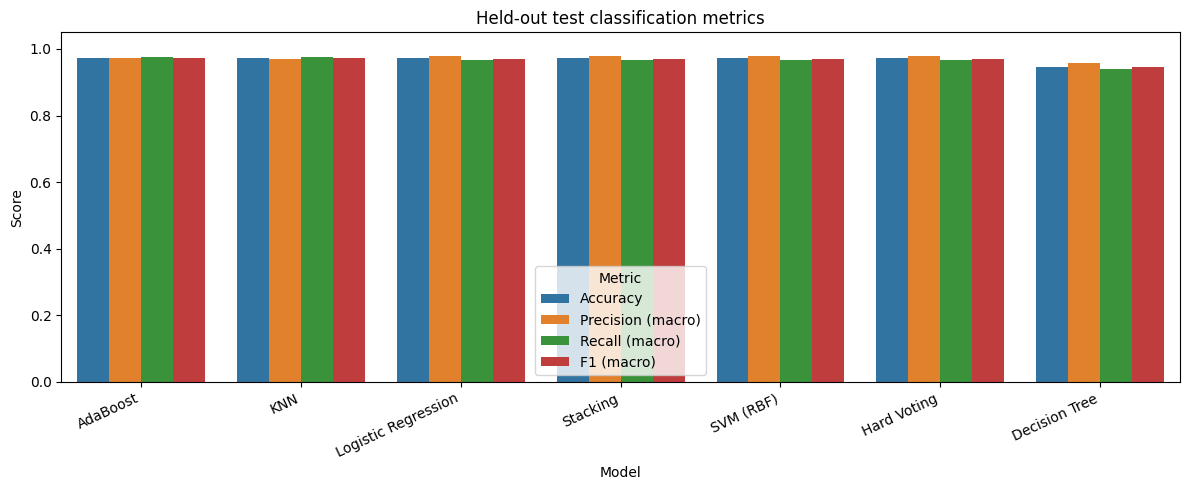

In [13]:
metrics = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"]
long = test_results.melt(id_vars="Model", value_vars=metrics,
                         var_name="Metric", value_name="Score")
plt.figure(figsize=(12, 5))
sns.barplot(data=long, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05); plt.xticks(rotation=25, ha="right")
plt.title("Held-out test classification metrics")
plt.tight_layout(); plt.show()

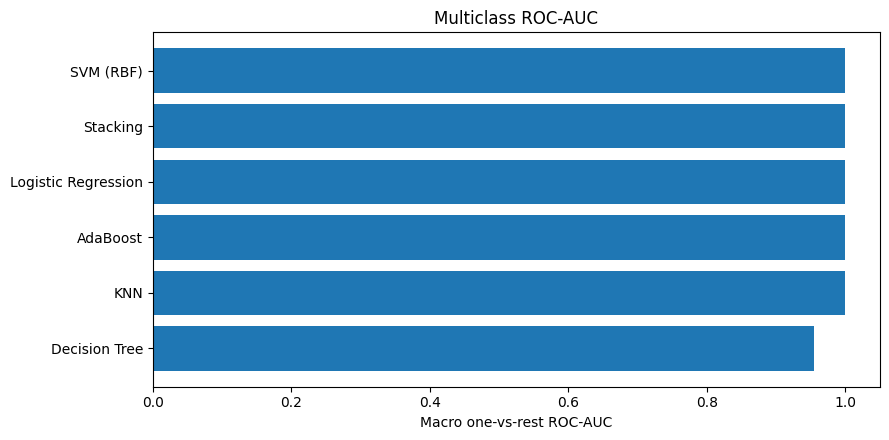

In [14]:
auc = test_results.dropna(subset=["ROC-AUC (OvR macro)"]).sort_values("ROC-AUC (OvR macro)")
plt.figure(figsize=(9, 4.5))
plt.barh(auc["Model"], auc["ROC-AUC (OvR macro)"])
plt.xlim(0, 1.05); plt.xlabel("Macro one-vs-rest ROC-AUC")
plt.title("Multiclass ROC-AUC")
plt.tight_layout(); plt.show()

## 12. Prediction diversity among base classifiers

Ensembles benefit when their component learners make complementary errors. The following agreement/disagreement matrices compare the four baseline models' predicted classes on the same test observations. Disagreement can indicate diversity, but diversity alone is not evidence of improved accuracy.

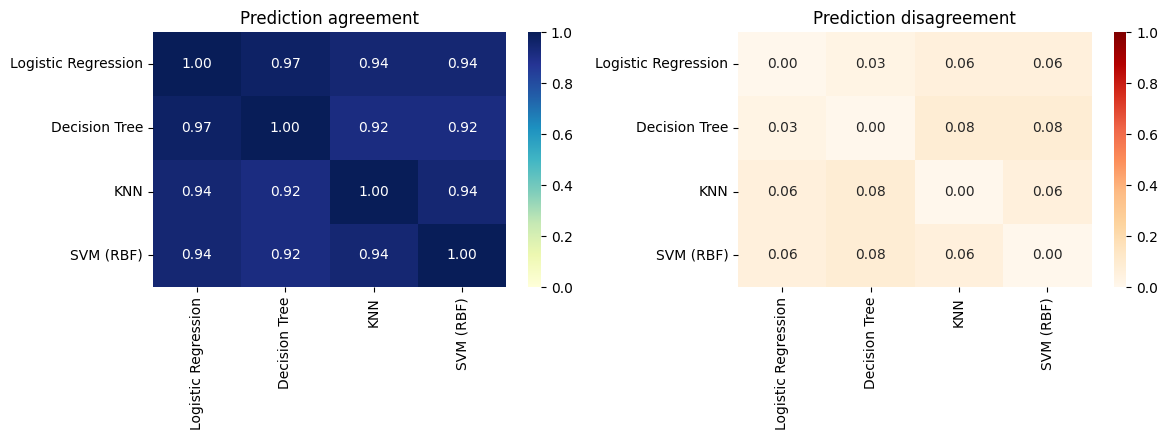

In [15]:
names = list(base_models)
agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        agree.loc[a,b] = np.mean(preds[a] == preds[b])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(agree, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax[0])
ax[0].set_title("Prediction agreement")
sns.heatmap(1-agree, annot=True, fmt=".2f", cmap="OrRd", vmin=0, vmax=1, ax=ax[1])
ax[1].set_title("Prediction disagreement")
plt.tight_layout(); plt.show()

## 13. Evidence-based findings

The following cell identifies the best model from the measured results. It does not hard-code a winner. Compare the best ensemble with the best individual classifier, and check whether the cross-validation ranking supports the held-out test result.

In [16]:
best_test = test_results.iloc[0]
best_cv = cv_results.iloc[0]
individual = test_results[test_results["Model"].isin(names)].sort_values("F1 (macro)", ascending=False).iloc[0]
ensemble = test_results[test_results["Model"].isin(["Stacking","AdaBoost","Hard Voting"])].sort_values("F1 (macro)", ascending=False).iloc[0]
best_auc = test_results.dropna(subset=["ROC-AUC (OvR macro)"]).sort_values("ROC-AUC (OvR macro)", ascending=False).iloc[0]
print(f"Best test macro F1: {best_test['Model']} = {best_test['F1 (macro)']:.4f}")
print(f"Best CV macro F1: {best_cv['Model']} = {best_cv['CV Macro F1']:.4f}")
print(f"Best test ROC-AUC: {best_auc['Model']} = {best_auc['ROC-AUC (OvR macro)']:.4f}")
print(f"Best individual: {individual['Model']} = {individual['F1 (macro)']:.4f}")
print(f"Best ensemble: {ensemble['Model']} = {ensemble['F1 (macro)']:.4f}")
print(f"Ensemble minus best individual macro F1: {ensemble['F1 (macro)']-individual['F1 (macro)']:+.4f}")

Best test macro F1: AdaBoost = 0.9743
Best CV macro F1: SVM (RBF) = 0.9865
Best test ROC-AUC: Stacking = 1.0000
Best individual: KNN = 0.9718
Best ensemble: AdaBoost = 0.9743
Ensemble minus best individual macro F1: +0.0025


## 14. When to use each method

| Method | Use when | Main strengths | Main limitations |
|---|---|---|---|
| Stacking | Several strong, diverse base models are available and there is enough data | Learns how to combine model outputs; flexible | More complex and computationally expensive; requires leakage-safe out-of-fold meta-features |
| AdaBoost | Weak learners perform better than chance and difficult examples deserve more attention | Sequentially improves weak learners; shallow trees are simple | Sensitive to mislabeled observations/outliers; sequential training is less parallel |
| Hard voting | Multiple models already exist and a simple combination is desired | Easy to explain and implement; no meta-model | Ignores confidence; each estimator gets one vote; ties can occur |
| Single model | One classifier is competitive and simplicity matters | Easier to explain, deploy and maintain | May not capture complementary strengths of other models |

A single model should be preferred if ensemble gains are negligible relative to added cost and complexity.

## 15. Critical evaluation, ethics and further research

### Limitations
1. The dataset has only 178 observations; this is a teaching-scale experiment, not production evidence.
2. A single hold-out split has sampling variability. Training-only cross-validation supplements it but does not replace external validation.
3. Hyperparameters are reasonable baseline choices, not exhaustive tuning results.
4. Macro F1 is appropriate when classes matter equally; other applications may have unequal error costs.
5. Probability estimates may not be perfectly calibrated. ROC-AUC measures ranking, not calibration.
6. AdaBoost can emphasize noisy or mislabeled observations.
7. Ensemble diversity helps only when errors are complementary and the combination improves generalisation.

### Ethical considerations
The dataset and models are used for educational classification. Predictions must not be represented as proof of wine quality, authenticity, safety or regulatory compliance. Real-world use would require domain validation, reliable data provenance, measurement quality checks and transparent communication of uncertainty.

### Future improvements
- Use nested cross-validation and tune hyperparameters with GridSearchCV/RandomizedSearchCV.
- Compare hard voting with soft voting and calibrated probabilities.
- Try alternative stacking meta-classifiers.
- Compare AdaBoost with Gradient Boosting and Random Forest.
- Use permutation importance to understand influential measurements.
- Evaluate probability calibration with reliability diagrams and Brier score.
- Repeat experiments over multiple seeds and report confidence intervals.
- Test robustness to noise, missing data and feature perturbations.

## 16. Conclusion

This experiment implemented stacking with a Logistic Regression meta-classifier, AdaBoost with decision-tree stumps, and a hard majority-voting classifier, and compared them with Logistic Regression, Decision Tree, KNN and RBF-SVM baselines. It used exploratory analysis, stratified splitting, pipeline-based scaling, training-only cross-validation and a held-out test set. Accuracy, macro precision, recall, F1, weighted F1, multiclass ROC-AUC, confusion matrices and runtime were examined.

The best approach must be selected from the measured comparison table according to the actual objective. Stacking is appropriate when diverse base learners and sufficient data are available; AdaBoost is useful when sequential reweighting improves weak learners; hard voting is a simple way to aggregate existing models. A single model remains preferable when it performs similarly with lower complexity.

### References
1. Scikit-learn Wine dataset: https://scikit-learn.org/stable/datasets/toy_dataset.html#wine-recognition-dataset
2. StackingClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html
3. AdaBoostClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html
4. VotingClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html
5. Model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html

### Assignment checklist
- [x] Stacking with meta-classifier
- [x] AdaBoost with selected weak base learner
- [x] Hard majority voting
- [x] Individual base classifier baselines
- [x] Classification metrics and confusion matrices
- [x] Comparative charts and evidence-based discussion
- [x] Use cases, limitations, ethics and future work